<a href="https://colab.research.google.com/github/LeylahfrA01178568/2039_data_visualization/blob/main/A6_intermediate_presentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The relationship between lifestyle habits, physical activity, and weight classification

**Leylah Fragoso Carvajal #A01178568**


*INDEX:*
1. [Describing the dataset](#scrollTo=ICeIJrvwv4jm&line=1&uniqifier=1)
2. [Describing the variables of interest](#scrollTo=F9owDlztv7N8&line=1&uniqifier=1)
3. [Q1: How are individuals distributed across different weight classifications?](#scrollTo=zhbaN-S_wE3X&line=1&uniqifier=1) **Pie Chart**
4. [Q2: How does the percentage of individuals classified with obesity differ depending on their family overweight history?](#scrollTo=8rO55TFrxAPO&line=2&uniqifier=1) **Bar Chart**



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
path = '/content/ObesityDataSet_raw_and_data_sinthetic.csv'
df = pd.read_csv(path)
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


# [1. Describing the data set](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)

The dataset describes individuals' eating habits, physical activity, family history, and physical characteristics, along with their corresponding weight classifications. It includes variables related to food consumption, daily water intake, meal frequency, and transportation habits.

**Important limitation:** The dataset contains both collected and synthetically generated observations. Therefore, the distribution of weight classifications should not be interpreted as representative of obesity prevalence in the general population.

**Dataset's Name:** Estimation of Obesity Levels Based On Eating Habits and Physical Condition

**Source:**
[UC Irvine’s Machine Learning Repository](https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition )


**Data Type:** Categorical, Numerical (continuous and integers) and Binary


**Observations:** 2111 observations

**Unit of obervation:** Each row represents one individual's physical characteristics, eating habits, lifestyle information, and weight classification.

## 1.1 Introduction to the dataset



In [ ]:
df.shape

(2111, 17)

In [ ]:
print('The data set has: \n',df.shape[0], 'observations and ', df.shape[1], ' columns')

The data set has: 
 2111 observations and  17  columns


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

In [ ]:

for col in df.columns:

    if df[col].dtype == 'object':
        if df[col].nunique() == 2:
            print(col, ": Binary")
        else:
            print(col, ": Categorical")

    elif df[col].dtype == 'int64':
        print(col, ": Integer")

    elif df[col].dtype == 'float64':
        print(col, ": Continuous")

Gender : Binary
Age : Continuous
Height : Continuous
Weight : Continuous
family_history_with_overweight : Binary
FAVC : Binary
FCVC : Continuous
NCP : Continuous
CAEC : Categorical
SMOKE : Binary
CH2O : Continuous
SCC : Binary
FAF : Continuous
TUE : Continuous
CALC : Categorical
MTRANS : Categorical
NObeyesdad : Categorical


## 1.2 Data Quality

In this section, I checked for missing and duplicated observations to assess data quality.

### Null values

In [ ]:
df.isnull().sum()

,0
Gender,0
Age,0
Height,0
Weight,0
family_history_with_overweight,0
FAVC,0
FCVC,0
NCP,0
CAEC,0
SMOKE,0


In [ ]:
df.dropna(inplace=True)
df.shape

(2111, 17)

Even after double checking, by eliminating the rows that have at least one missing value. As seen in the previous code line, the shape of the data frame is the same as the original. There for it had no missing values.

### Duplicated values

In [ ]:
df.duplicated().sum()

np.int64(24)

In [ ]:
print('The data set has:\n', df.duplicated().sum(), 'duplicated observations')

The data set has:
 24 duplicated observations


In [ ]:
df.drop_duplicates(inplace=True)
ndf = df.copy()
ndf

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.000000,1.620000,64.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,0.000000,1.000000,no,Public_Transportation,Normal_Weight
1,Female,21.000000,1.520000,56.000000,yes,no,3.0,3.0,Sometimes,yes,3.000000,yes,3.000000,0.000000,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.000000,1.800000,77.000000,yes,no,2.0,3.0,Sometimes,no,2.000000,no,2.000000,1.000000,Frequently,Public_Transportation,Normal_Weight
3,Male,27.000000,1.800000,87.000000,no,no,3.0,3.0,Sometimes,no,2.000000,no,2.000000,0.000000,Frequently,Walking,Overweight_Level_I
4,Male,22.000000,1.780000,89.800000,no,no,2.0,1.0,Sometimes,no,2.000000,no,0.000000,0.000000,Sometimes,Public_Transportation,Overweight_Level_II
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2106,Female,20.976842,1.710730,131.408528,yes,yes,3.0,3.0,Sometimes,no,1.728139,no,1.676269,0.906247,Sometimes,Public_Transportation,Obesity_Type_III
2107,Female,21.982942,1.748584,133.742943,yes,yes,3.0,3.0,Sometimes,no,2.005130,no,1.341390,0.599270,Sometimes,Public_Transportation,Obesity_Type_III
2108,Female,22.524036,1.752206,133.689352,yes,yes,3.0,3.0,Sometimes,no,2.054193,no,1.414209,0.646288,Sometimes,Public_Transportation,Obesity_Type_III
2109,Female,24.361936,1.739450,133.346641,yes,yes,3.0,3.0,Sometimes,no,2.852339,no,1.139107,0.586035,Sometimes,Public_Transportation,Obesity_Type_III


In [ ]:
ndf.shape

(2087, 17)

In [ ]:
print ('After dropping duplicated values, the data set has:\n',ndf.shape[0],'rows and ', ndf.shape[1], ' columns')

After dropping duplicated values, the data set has:
 2087 rows and  17  columns


# [2. Describing the variables of interest](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)

In this section I'll and keep only the variables that interest me, given my research topic.

**Variables of Interest**
1.  **family_history:**
  Indicates whether an individual has family members who currently have or previously had overweight. *(Binary)*
2.  **Weight_class:** Represents an individual's weight classification, ranging from insufficient weight to different obesity levels. *(Categorical)*

  
3.  **High_calorie:** Indicates whether an individual frequently consumes high-calorie foods. *(Binary)*
4.  **Veggies_freq:** Measures how frequently an individual consumes vegetables in their meals. *(Numerical)*
5.  **Daily_meals:** Represents the number of main meals an individual consumes daily.*(Numerical)*
6.  **Water_intake**  Represents an individual's reported daily water consumption. *(Numerical)*
7.  **Physical_Act:** Measures how frequently an individual engages in physical activity. *(Numerical)*
8.  **MTRANS**  Identifies the transportation method an individual usually uses. *(Categorical)*




In [33]:
# Select variables of interest

interest_variables = [
    'family_history_with_overweight',
    'FAVC', 'FCVC', 'NCP', 'CH2O',
    'FAF', 'MTRANS', 'NObeyesdad'
]

# update data set with variables of interest
ndf = df[interest_variables].copy()

# Rename variables
ndf.rename(columns={
    'family_history_with_overweight': 'family_history',
    'FAVC': 'High_calorie',
    'FCVC': 'Veggies_freq',
    'NCP': 'Daily_meals',
    'CH2O': 'Water_intake',
    'FAF': 'Physical_Act',
    'NObeyesdad': 'Weight_class'
}, inplace=True)

ndf.head()

,family_history,High_calorie,Veggies_freq,Daily_meals,Water_intake,Physical_Act,MTRANS,Weight_class
0,yes,no,2.0,3.0,2.0,0.0,Public_Transportation,Normal_Weight
1,yes,no,3.0,3.0,3.0,3.0,Public_Transportation,Normal_Weight
2,yes,no,2.0,3.0,2.0,2.0,Public_Transportation,Normal_Weight
3,no,no,3.0,3.0,2.0,2.0,Walking,Overweight_Level_I
4,no,no,2.0,1.0,2.0,0.0,Public_Transportation,Overweight_Level_II


In [30]:
# Classify variables based on their values

variable_types = {}

for col in ndf.columns:

    if ndf[col].nunique() == 2:
        var_type = 'Binary'

    elif ndf[col].dtype == 'object':
        var_type = 'Categorical'

    else:
        var_type = 'Numerical'

    variable_types[col] = var_type

In [31]:
variables_table = pd.DataFrame({
    'Variable': ndf.columns,

    'Meaning': [
        'Family history of overweight',
        'Frequent consumption of high-calorie food',
        'Frequency of vegetable consumption',
        'Number of main meals per day',
        'Daily water consumption',
        'Frequency of physical activity',
        'Usual transportation method',
        'Weight classification'
    ],

    'Unit / Categories': [
        'Yes / No',
        'Yes / No',
        'Frequency scale (1-3)',
        'Meals/day',
        'Intake scale (1-3)',
        'Activity frequency scale (0-3)',
        'Walking, Bike, Motorbike, Automobile, Public Transportation',
        'Underweight, Normal weight, Overweight I-II, Obesity I-III'
    ]
})

# Add previously identified types
variables_table['Type'] = variables_table['Variable'].map(variable_types)

# Arrange columns
variables_table = variables_table[
    ['Variable', 'Meaning', 'Type', 'Unit / Categories']
]

display(variables_table)

,Variable,Meaning,Type,Unit / Categories
0,family_history,Family history of overweight,Binary,Yes / No
1,High_calorie,Frequent consumption of high-calorie food,Binary,Yes / No
2,Veggies_freq,Frequency of vegetable consumption,Numerical,Frequency scale (1-3)
3,Daily_meals,Number of main meals per day,Numerical,Meals/day
4,Water_intake,Daily water consumption,Numerical,Intake scale (1-3)
5,Physical_Act,Frequency of physical activity,Numerical,Activity frequency scale (0-3)
6,MTRANS,Usual transportation method,Categorical,"Walking, Bike, Motorbike, Automobile, Public T..."
7,Weight_class,Weight classification,Categorical,"Underweight, Normal weight, Overweight I-II, O..."


# [3. Q1: How are individuals distributed across different weight classifications?]((#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1)) **Pie chart**

**Study/Analysis:** Calculate the number and percentage of individuals belonging to each weight classification. In order to identify which groups is more "present" in the dataset".

## 3.1 Pivot table

To count how many individuals fall into each of the NObeyesda categories.


In [ ]:
weight_gp_count = pd.pivot_table(
    ndf,
    index='NObeyesdad',
    aggfunc='size'
).reset_index(name='count_WeightGP')

weight_gp_count

,NObeyesdad,count_WeightGP
0,Insufficient_Weight,267
1,Normal_Weight,282
2,Obesity_Type_I,351
3,Obesity_Type_II,297
4,Obesity_Type_III,324
5,Overweight_Level_I,276
6,Overweight_Level_II,290


## 3.2 Figure 1.- Pie chart

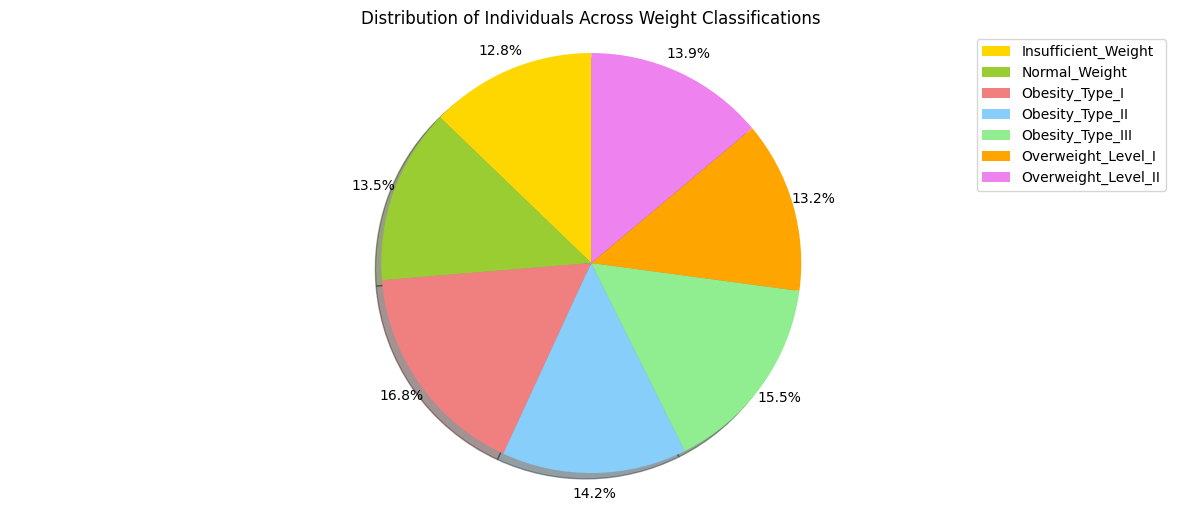

In [ ]:


colors_list = ['gold', 'yellowgreen', 'lightcoral',
               'lightskyblue', 'lightgreen', 'orange', 'violet']

explode_list = [0, 0, 0, 0, 0, 0, 0]

# Plot the pie chart

weight_gp_count['count_WeightGP'].plot(
    kind='pie',
    figsize=(15, 6),
    autopct='%1.1f%%',
    startangle=90,
    shadow=True,
    labels=None,
    pctdistance=1.1,
    explode=explode_list,
    colors=colors_list
)

plt.axis('equal')

plt.legend(
    labels=weight_gp_count['NObeyesdad'],
    bbox_to_anchor=(1.0, 1.0)
)

plt.title('Distribution of Individuals Across Weight Classifications')
plt.ylabel('')
plt.show()

### 3.3 Insights

1. Obesity Type I had the highest proportion (16.8%), exceeding the Normal Weight group (13.5%) by 3.3 percentage points.

2. Insufficient Weight (12.8%) and Normal Weight (13.5%) represented the two smallest groups.

# [4. Q2: How does the percentage of individuals classified with obesity differ depending on their family overweight history?](#scrollTo=u9q-QGBEvqn_&line=10&uniqifier=1) **Bar Chart**


**Study/Analysis:** Calculate the percentage of individuals classified with obesity within each family history group in order to compare obesity prevalence between the two groups.


### 4.1 Identify people with any type of obesity

In [ ]:
ndf['has_obesity'] = ndf['NObeyesdad'].isin([
    'Obesity_Type_I',
    'Obesity_Type_II',
    'Obesity_Type_III'
])

ndf.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad,has_obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight,False
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight,False
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight,False
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I,False
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II,False


### 4.2 Pivot table to count observations by family history and obesity classification

In [ ]:


family_gp_count = pd.pivot_table(
    ndf,
    index='family_history_with_overweight',
    columns='has_obesity',
    aggfunc='size',
    fill_value=0
)

family_gp_count

has_obesity,False,True
family_history_with_overweight,,
no,357,8
yes,758,964


In [ ]:
# Calculate obesity percentage within each family history group

family_gp_count['Obesity_Percentage'] = (
    family_gp_count[True] /
    family_gp_count.sum(axis=1) * 100
)

family_gp_count

has_obesity,False,True,Obesity_Percentage
family_history_with_overweight,,,
no,357,8,2.191781
yes,758,964,55.981417


### 4.3 Figure 2.- Bar chart

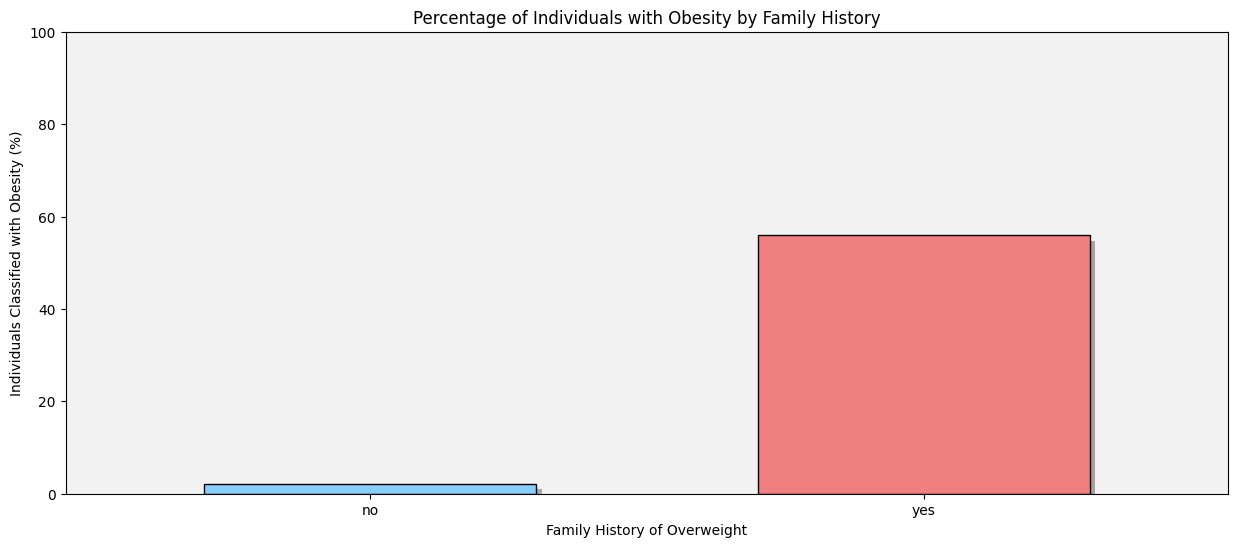

In [ ]:
import matplotlib.patheffects as pe

colors_list = ['lightskyblue', 'lightcoral']

ax = family_gp_count['Obesity_Percentage'].plot(
    kind='bar',
    figsize=(15, 6),
    color=colors_list,
    edgecolor='black',
    width=0.6
)

# Set light grey background
ax.set_facecolor('#F2F2F2')

# Add shadows
for bar in ax.patches:
    bar.set_path_effects([
        pe.SimplePatchShadow(offset=(4, -4), alpha=0.4),
        pe.Normal()
    ])

plt.title('Percentage of Individuals with Obesity by Family History')
plt.xlabel('Family History of Overweight')
plt.ylabel('Individuals Classified with Obesity (%)')
plt.xticks(rotation=0)
plt.ylim(0, 100)

plt.show()

### 4.4 Insight

- Individuals with a family history of overweight had a considerably higher percentage classified with obesity (56.0%) compared to those without a family history (2.2%).

